<a href="https://colab.research.google.com/github/KwancheolShin/introduction-to-deep-learning/blob/main/multiclass_mnist/mnist_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST 다중분류: NumPy로 만든 다층 신경망

층(Affine, ReLU, Softmax-with-loss)을 NumPy로 직접 만들고, 은닉층 구성이 다른 두 network를 학습해 검증 데이터로 고른 뒤 시험 데이터로 한 번 평가한다. 원본: `mnist_mlp.py`

* 셀을 위에서부터 차례로 실행한다 (Shift+Enter). 앞 셀에서 만든 변수는 다음 셀에서 그대로 쓸 수 있다.
* 그림은 작업 폴더의 `figures/`에도 저장된다 (Colab의 작업 폴더는 `/content`이며, 세션이 끝나면 지워진다).


## 0. Setup

In [1]:
# Week: Multi-class Classification -- extended lab (for Assignment 2)
# Deeper networks built from the SAME layer classes as mnist_lab.py.
#   * MultiLayerNet: any number of hidden layers, given as a list of widths
#   * train / validation split
#   * compare several settings on the validation set, then test ONCE at the end
# Run this file from its own folder; figures are saved to ./figures/*.png
#   Cells: each '# %%' starts a cell. In VS Code, Run Cell (Shift+Enter) sends one cell to the
#   Interactive window (variables stay in the kernel); 'python <file>' still runs the whole file.

import os
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
os.makedirs("figures", exist_ok=True)

## 1. Data

In [2]:
# =====================================================
# 1. Data: load, flatten, normalize, one-hot, train/validation split
# =====================================================
def load_mnist():
    """Return (x_train, t_train), (x_test, t_test): images (N,28,28), labels (N,)."""
    try:
        from tensorflow.keras.datasets import mnist   # if TensorFlow is installed
        return mnist.load_data()
    except ImportError:
        from sklearn.datasets import fetch_openml     # otherwise download from OpenML
        X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
        X = X.reshape(-1, 28, 28).astype(np.uint8)
        y = y.astype(np.int64)
        return (X[:60000], y[:60000]), (X[60000:], y[60000:])

(x_all_o, t_all_o), (x_test_o, t_test_o) = load_mnist()

x_all  = x_all_o.reshape(x_all_o.shape[0], -1) / 255.0      # (60000, 784)
x_test = x_test_o.reshape(x_test_o.shape[0], -1) / 255.0    # (10000, 784)
t_all  = np.eye(10)[t_all_o]                                 # (60000, 10)
t_test = np.eye(10)[t_test_o]                                # (10000, 10)

# hold out 5000 training images as a VALIDATION set:
# we choose the network / hyper-parameters with it, and keep the test set for the very end
perm = np.random.permutation(x_all.shape[0])
val_idx, train_idx = perm[:5000], perm[5000:]
x_train, t_train = x_all[train_idx], t_all[train_idx]       # (55000, 784)
x_val,   t_val   = x_all[val_idx],   t_all[val_idx]         # (5000, 784)
print("train:", x_train.shape, " validation:", x_val.shape, " test:", x_test.shape)

train: (55000, 784)  validation: (5000, 784)  test: (10000, 784)


## 2. Layers

In [3]:
# =====================================================
# 2. Layers (identical to mnist_lab.py)
# =====================================================
class Affine:
    """A = X W + B  for a mini-batch X of shape (h, l)."""
    def __init__(self, W, B):
        self.W = W          # (l, m)
        self.B = B          # (1, m)
        self.X = None
        self.dW = None
        self.dB = None

    def forward(self, X):
        self.X = X
        return X @ self.W + self.B          # (h,l)@(l,m) + (1,m) -> (h, m)

    def backward(self, dA):
        self.dW = self.X.T @ dA                          # (l,h)@(h,m) -> (l, m)
        self.dB = np.sum(dA, axis=0, keepdims=True)      # sum over rows -> (1, m)
        return dA @ self.W.T                             # dL/dX : (h, l)


class Relu:
    def __init__(self):
        self.mask = None

    def forward(self, A):
        self.mask = (A > 0)
        return np.where(self.mask, A, 0.0)

    def backward(self, dZ):
        return np.where(self.mask, dZ, 0.0)


class Sigmoid:
    def __init__(self):
        self.Z = None

    def forward(self, A):
        self.Z = 1.0 / (1.0 + np.exp(-A))
        return self.Z

    def backward(self, dZ):
        return dZ * self.Z * (1.0 - self.Z)


def softmax(U):
    U = U - np.max(U, axis=1, keepdims=True)
    expU = np.exp(U)
    return expU / np.sum(expU, axis=1, keepdims=True)


class SoftmaxWithCrossEntropy:
    def __init__(self):
        self.Y = None
        self.T = None

    def forward(self, U, T):
        self.T = T
        self.Y = softmax(U)
        h = U.shape[0]
        return -np.sum(T * np.log(self.Y + 1e-12)) / h

    def backward(self):
        h = self.T.shape[0]
        return (self.Y - self.T) / h        # the ONLY place where we divide by h


class SoftmaxWithSquaredError:
    def __init__(self):
        self.Y = None
        self.T = None

    def forward(self, U, T):
        self.T = T
        self.Y = softmax(U)
        h = U.shape[0]
        return 0.5 * np.sum((self.Y - self.T) ** 2) / h

    def backward(self):
        h = self.T.shape[0]
        R = self.Y - self.T
        return self.Y * (R - np.sum(self.Y * R, axis=1, keepdims=True)) / h

## 3. Multi-layer network

In [4]:
# =====================================================
# 3. Multi-layer network: X -> [Affine -> act] x k -> Affine -> Softmax-loss
# =====================================================
class MultiLayerNet:
    def __init__(self, input_size, hidden_sizes, output_size,
                 activation="relu", loss="ce", weight_init_std=0.05):
        sizes = [input_size] + list(hidden_sizes) + [output_size]   # e.g. [784, 256, 128, 10]
        self.params = {}
        self.layers = []
        for i in range(len(sizes) - 1):
            n_in, n_out = sizes[i], sizes[i + 1]
            W = weight_init_std * np.random.randn(n_in, n_out)   # (input nodes, output nodes)
            B = np.zeros((1, n_out))
            self.params[f"W{i + 1}"] = W
            self.params[f"B{i + 1}"] = B
            self.layers.append(Affine(W, B))
            if i < len(sizes) - 2:                     # no activation after the last Affine
                self.layers.append(Relu() if activation == "relu" else Sigmoid())
        self.last = SoftmaxWithCrossEntropy() if loss == "ce" else SoftmaxWithSquaredError()

    def predict(self, X):                     # scores U
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def loss(self, X, T):
        return self.last.forward(self.predict(X), T)

    def backward(self):                       # call right after loss()
        d = self.last.backward()
        for layer in reversed(self.layers):   # the same rule, layer after layer
            d = layer.backward(d)
        grads, k = {}, 1
        for layer in self.layers:
            if isinstance(layer, Affine):
                grads[f"W{k}"], grads[f"B{k}"] = layer.dW, layer.dB
                k += 1
        return grads

    def accuracy(self, X, T):
        U = self.predict(X)
        return np.mean(np.argmax(U, axis=1) == np.argmax(T, axis=1))

    def num_params(self):
        return sum(p.size for p in self.params.values())

## 4. Training function

In [5]:
# =====================================================
# 4. Training with mini-batches (one epoch = every training image once)
# =====================================================
def train(network, epochs=20, batch_size=100, learning_rate=0.1, name=""):
    N = x_train.shape[0]
    iter_per_epoch = N // batch_size
    hist = {"loss": [], "train_acc": [], "val_acc": []}
    t0 = time.time()
    for epoch in range(epochs):
        perm = np.random.permutation(N)
        for it in range(iter_per_epoch):
            idx = perm[it * batch_size:(it + 1) * batch_size]
            loss = network.loss(x_train[idx], t_train[idx])
            grads = network.backward()
            for key in network.params:
                network.params[key] -= learning_rate * grads[key]
            hist["loss"].append(loss)
        hist["train_acc"].append(network.accuracy(x_train, t_train))
        hist["val_acc"].append(network.accuracy(x_val, t_val))
        print(f"[{name}] epoch {epoch + 1:2d}: loss={loss:.4f}, "
              f"train acc={hist['train_acc'][-1]:.4f}, val acc={hist['val_acc'][-1]:.4f} "
              f"({time.time() - t0:.0f}s)")
    return hist

## 5. Experiments (takes a while)

In [6]:
# =====================================================
# 5. Experiments: change ONE thing at a time, compare on the validation set
# =====================================================
# Edit this list for Assignment 2. Each line is one experiment:
#   (name, hidden layer widths, activation, loss, learning rate, batch size)
# Change ONE thing at a time and compare the validation accuracy.
experiments = [
    ("A: [100]",      [100],      "relu", "ce", 0.1, 100),   # the network of the lab (Step 5)
    ("B: [100, 100]", [100, 100], "relu", "ce", 0.1, 100),   # one more hidden layer
]
epochs = 10

results = {}
for name, hidden, act, loss_type, lr, bs in experiments:
    np.random.seed(1)
    net = MultiLayerNet(784, hidden, 10, activation=act, loss=loss_type)
    print(f"\n{name}: {net.num_params()} parameters")
    hist = train(net, epochs=epochs, batch_size=bs, learning_rate=lr, name=name.split(":")[0])
    results[name] = (net, hist)


A: [100]: 79510 parameters


[A] epoch  1: loss=0.3415, train acc=0.9072, val acc=0.9090 (1s)


[A] epoch  2: loss=0.3203, train acc=0.9331, val acc=0.9354 (1s)


[A] epoch  3: loss=0.1720, train acc=0.9450, val acc=0.9464 (2s)


[A] epoch  4: loss=0.3185, train acc=0.9526, val acc=0.9516 (3s)


[A] epoch  5: loss=0.1817, train acc=0.9588, val acc=0.9564 (3s)


... (11 outputs left out)

[B] epoch  7: loss=0.0504, train acc=0.9782, val acc=0.9704 (9s)


[B] epoch  8: loss=0.1128, train acc=0.9789, val acc=0.9720 (11s)


[B] epoch  9: loss=0.0504, train acc=0.9837, val acc=0.9732 (14s)


[B] epoch 10: loss=0.0509, train acc=0.9841, val acc=0.9738 (16s)


## 5'. Summary and learning curves


===== summary (validation accuracy after the last epoch) =====
A: [100]                        params=  79510  train=0.9763  val=0.9690
B: [100, 100]                   params=  89610  train=0.9841  val=0.9738


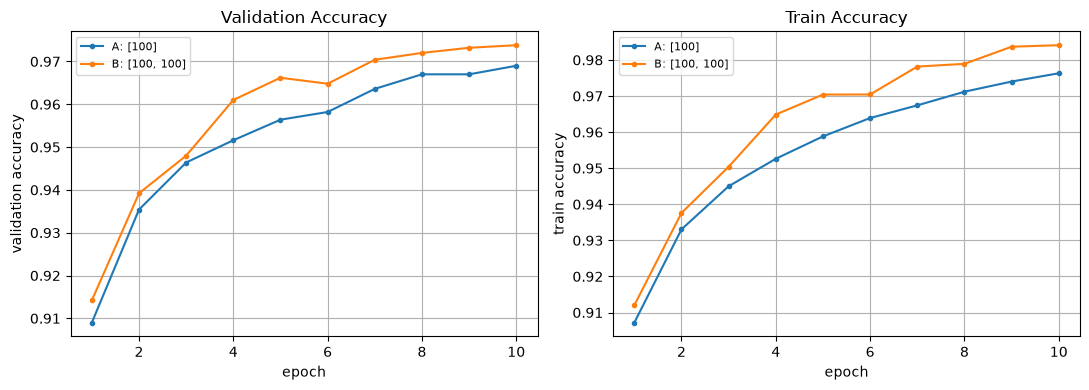

In [7]:
print("\n===== summary (validation accuracy after the last epoch) =====")
for name, (net, hist) in results.items():
    print(f"{name:30s}  params={net.num_params():7d}  "
          f"train={hist['train_acc'][-1]:.4f}  val={hist['val_acc'][-1]:.4f}")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
for name, (net, hist) in results.items():
    plt.plot(np.arange(1, epochs + 1), hist["val_acc"], "o-", markersize=3, label=name)
plt.xlabel("epoch")
plt.ylabel("validation accuracy")
plt.title("Validation Accuracy")
plt.legend(fontsize=8)
plt.grid(True)

plt.subplot(1, 2, 2)
for name, (net, hist) in results.items():
    plt.plot(np.arange(1, epochs + 1), hist["train_acc"], "o-", markersize=3, label=name)
plt.xlabel("epoch")
plt.ylabel("train accuracy")
plt.title("Train Accuracy")
plt.legend(fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/mlp_compare.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Final evaluation: test ONCE

In [8]:
# =====================================================
# 6. Final evaluation: pick the best on VALIDATION, then test ONCE
# =====================================================
best_name = max(results, key=lambda k: results[k][1]["val_acc"][-1])
best_net = results[best_name][0]
test_acc = best_net.accuracy(x_test, t_test)
print(f"\nbest on validation: {best_name}")
print(f"test accuracy of the chosen network: {test_acc:.4f}")


best on validation: B: [100, 100]
test accuracy of the chosen network: 0.9733


## 6'. Confusion matrix

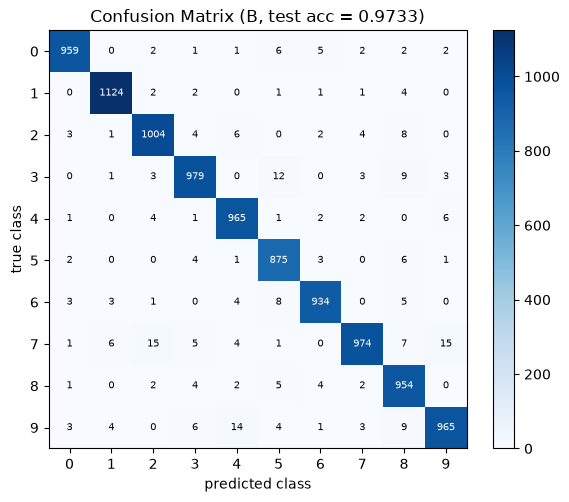

per-class test accuracy: [0.9786 0.9903 0.9729 0.9693 0.9827 0.9809 0.9749 0.9475 0.9795 0.9564]


In [9]:
# confusion matrix: row = true class, column = predicted class
pred = np.argmax(best_net.predict(x_test), axis=1)
C = np.zeros((10, 10), dtype=int)
for t, p in zip(t_test_o, pred):
    C[t, p] += 1

plt.figure(figsize=(6, 5))
plt.imshow(C, cmap="Blues")
for i in range(10):
    for j in range(10):
        plt.text(j, i, C[i, j], ha="center", va="center", fontsize=7,
                 color="white" if C[i, j] > C.max() / 2 else "black")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("predicted class")
plt.ylabel("true class")
plt.title(f"Confusion Matrix ({best_name[:1]}, test acc = {test_acc:.4f})")
plt.colorbar()
plt.tight_layout()
plt.savefig("figures/mlp_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

print("per-class test accuracy:",
      np.round(np.diag(C) / C.sum(axis=1), 4))